In [1]:
from google.colab import drive

drive.mount('/content/drive')
import os
from pathlib import Path

# Lokasi dataset
DATASET_DIR = Path(
    '/content/drive/MyDrive/Daun Cabai'
)

# Lokasi penyimpanan hasil penelitian
OUTPUT_DIR = Path(
    '/content/drive/MyDrive/Hasil_Penelitian_Cabai'
)

# Folder hasil untuk masing-masing model
BASELINE_DIR = OUTPUT_DIR / 'EfficientNetB0'
ATTENTION_DIR = OUTPUT_DIR / 'EfficientNetB0_CrossAttention'

# Membuat folder jika belum tersedia
BASELINE_DIR.mkdir(parents=True, exist_ok=True)
ATTENTION_DIR.mkdir(parents=True, exist_ok=True)

# Memeriksa keberadaan dataset
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f'Dataset tidak ditemukan: {DATASET_DIR}'
    )

print("Dataset ditemukan:", DATASET_DIR)
print("Hasil baseline:", BASELINE_DIR)
print("Hasil Cross-Attention:", ATTENTION_DIR)

Mounted at /content/drive
Dataset ditemukan: /content/drive/MyDrive/Daun Cabai
Hasil baseline: /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0
Hasil Cross-Attention: /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0_CrossAttention


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
from pathlib import Path

ImageFile.LOAD_TRUNCATED_IMAGES = False

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [3]:
IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp', '.webp'
}

records = []
corrupt_files = []

class_dirs = sorted([
    folder for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
])

for class_dir in class_dirs:

    image_paths = [
        file for file in class_dir.rglob('*')
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in image_paths:

        try:
            with Image.open(image_path) as img:
                img.verify()

            records.append({
                'filepath': str(image_path),
                'label': class_dir.name
            })

        except Exception as e:

            corrupt_files.append({
                'filepath': str(image_path),
                'error': str(e)
            })

df = pd.DataFrame(records)

print("================================")
print("HASIL PEMERIKSAAN DATASET")
print("================================")

print("Jumlah gambar valid:", len(df))
print("Jumlah gambar rusak:", len(corrupt_files))
print("Jumlah kelas:", df['label'].nunique())

print("\nJumlah gambar setiap kelas:")
print(df['label'].value_counts().sort_index())

HASIL PEMERIKSAAN DATASET
Jumlah gambar valid: 738
Jumlah gambar rusak: 0
Jumlah kelas: 3

Jumlah gambar setiap kelas:
label
Daun karat       336
Daun keriting    259
Daun sehat       143
Name: count, dtype: int64


In [4]:
if len(corrupt_files) > 0:

    print("Ditemukan gambar yang bermasalah:")

    for file in corrupt_files[:20]:
        print(file['filepath'])

else:

    print("Tidak ditemukan gambar yang rusak.")

Tidak ditemukan gambar yang rusak.


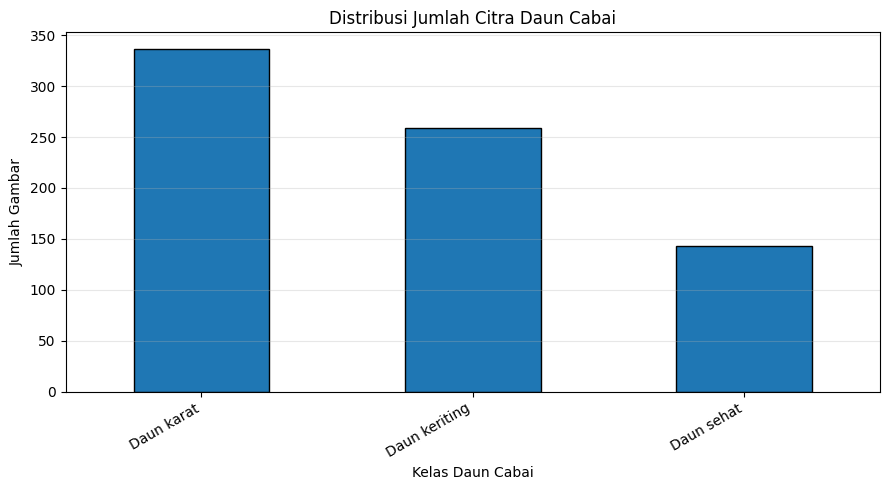

In [5]:
class_counts = (
    df['label']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

class_counts.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Distribusi Jumlah Citra Daun Cabai')
plt.xlabel('Kelas Daun Cabai')
plt.ylabel('Jumlah Gambar')

plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

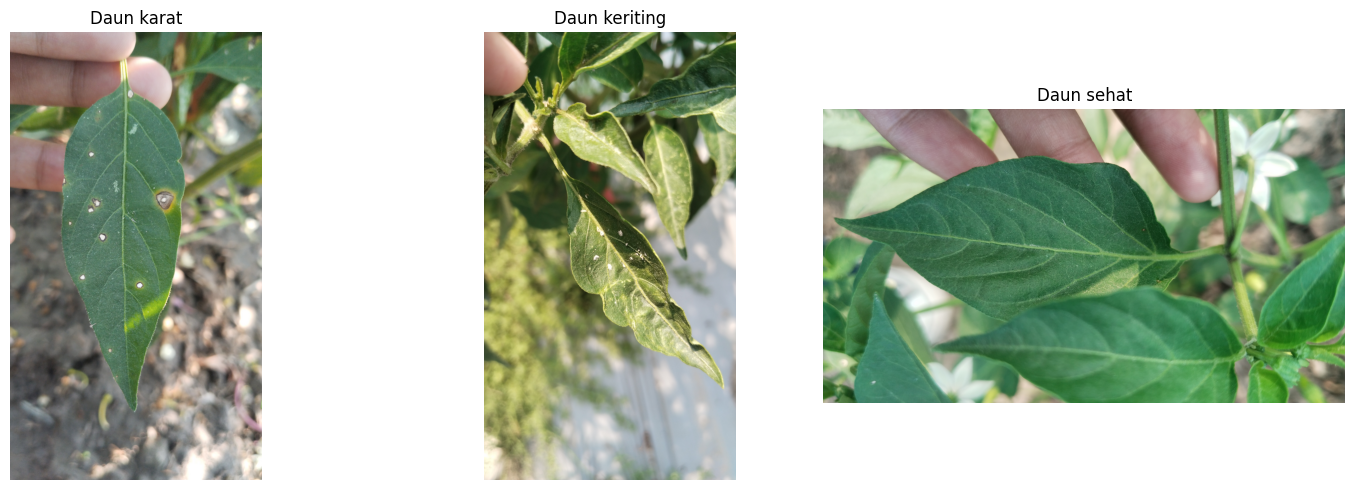

In [6]:
class_names = sorted(df['label'].unique())

fig, axes = plt.subplots(
    1,
    len(class_names),
    figsize=(15, 5)
)

if len(class_names) == 1:
    axes = [axes]

for ax, class_name in zip(axes, class_names):

    sample_path = (
        df[df['label'] == class_name]
        .sample(1, random_state=42)['filepath']
        .iloc[0]
    )

    with Image.open(sample_path) as img:
        ax.imshow(img.convert('RGB'))

    ax.set_title(class_name)
    ax.axis('off')

plt.tight_layout()
plt.show()

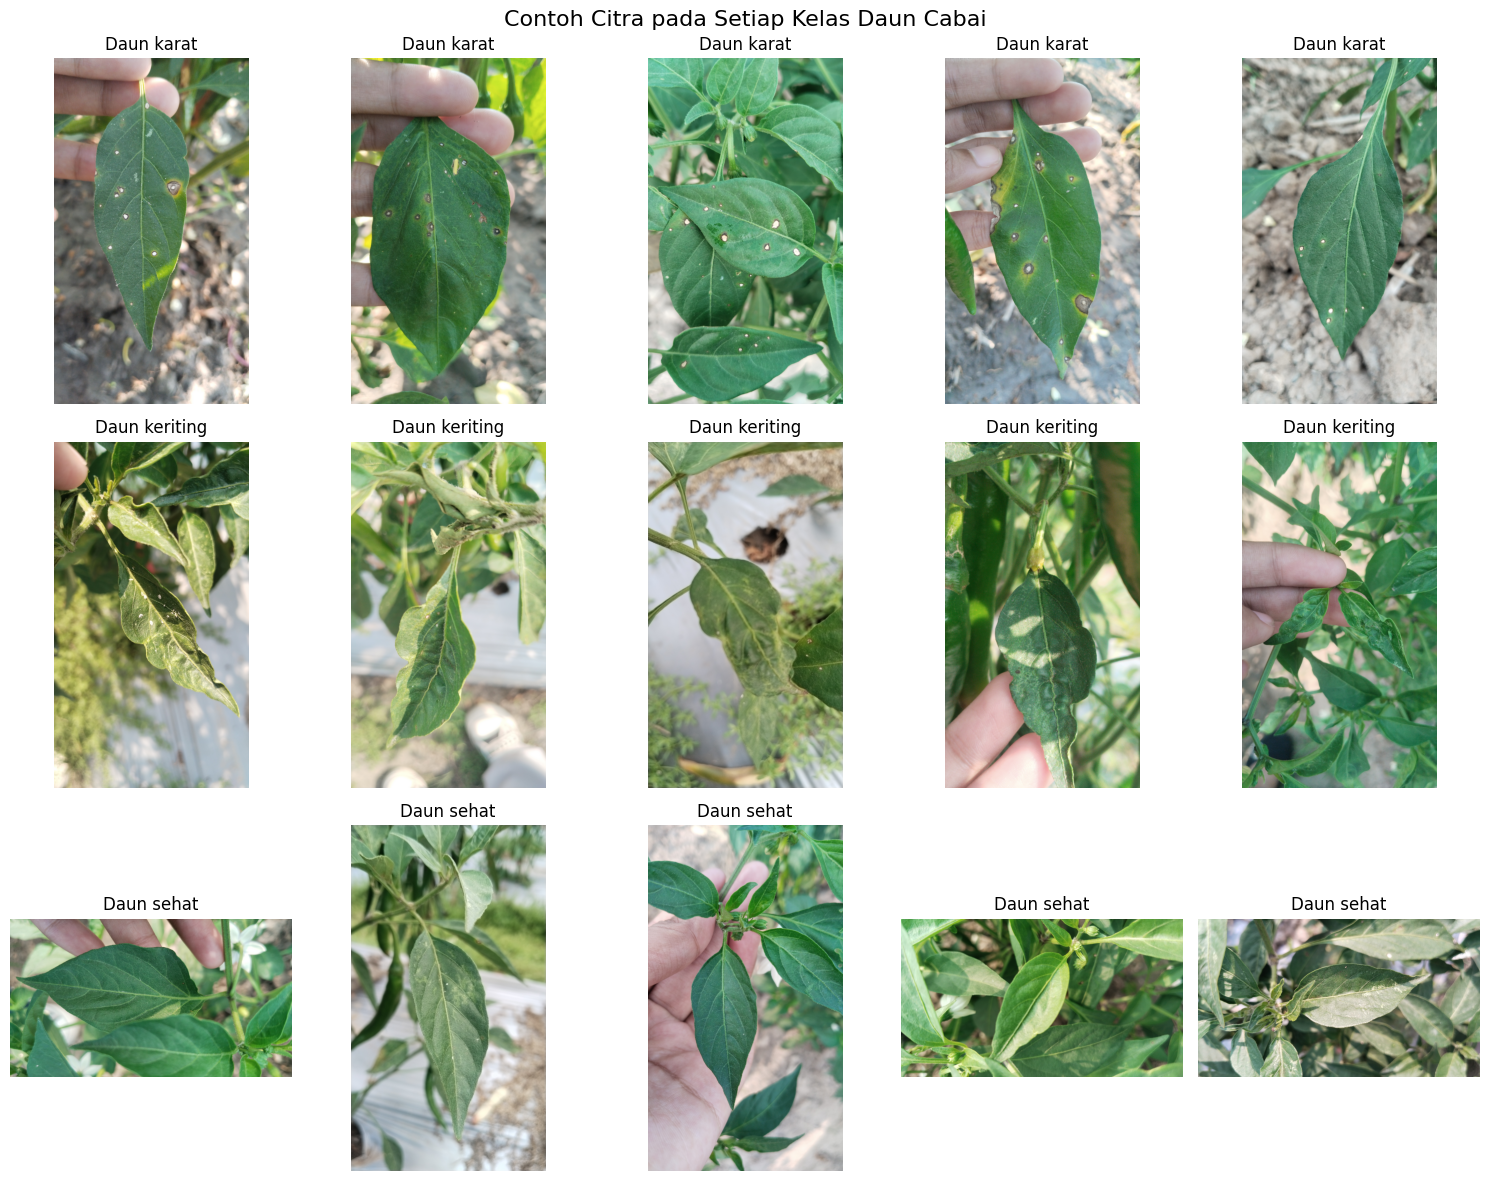

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import math

JUMLAH_CONTOH = 5
class_names = sorted(df['label'].unique())

fig, axes = plt.subplots(
    len(class_names),
    JUMLAH_CONTOH,
    figsize=(15, 4 * len(class_names))
)

for row, class_name in enumerate(class_names):

    data_kelas = df[df['label'] == class_name]

    jumlah_tampil = min(JUMLAH_CONTOH, len(data_kelas))

    sampel = data_kelas.sample(
        n=jumlah_tampil,
        random_state=42
    )

    for col in range(JUMLAH_CONTOH):

        ax = axes[row, col] if len(class_names) > 1 else axes[col]

        if col < jumlah_tampil:
            image_path = sampel.iloc[col]['filepath']

            with Image.open(image_path) as img:
                ax.imshow(img.convert('RGB'))

            ax.set_title(class_name)
        else:
            ax.axis('off')

        ax.axis('off')

plt.suptitle(
    'Contoh Citra pada Setiap Kelas Daun Cabai',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
image_sizes = []

for _, row in df.iterrows():

    image_path = row['filepath']

    try:
        with Image.open(image_path) as img:
            width, height = img.size

        image_sizes.append({
            'filepath': image_path,
            'label': row['label'],
            'width': width,
            'height': height
        })

    except Exception as e:
        print("Gagal membaca:", image_path, e)

df_sizes = pd.DataFrame(image_sizes)

print("Jumlah gambar yang berhasil diperiksa:", len(df_sizes))

print("\nStatistik ukuran gambar:")
print(df_sizes[['width', 'height']].describe())

print("\nContoh ukuran gambar:")
display(df_sizes.head(10))

Jumlah gambar yang berhasil diperiksa: 738

Statistik ukuran gambar:
             width       height
count   738.000000   738.000000
mean   2628.108401  3706.991870
std     710.859047   714.584718
min    1840.000000  1840.000000
25%    2296.000000  4080.000000
50%    2296.000000  4080.000000
75%    2296.000000  4080.000000
max    4080.000000  4080.000000

Contoh ukuran gambar:


,filepath,label,width,height
0,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
1,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
2,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
3,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
4,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
5,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
6,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
7,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
8,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080
9,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,2296,4080


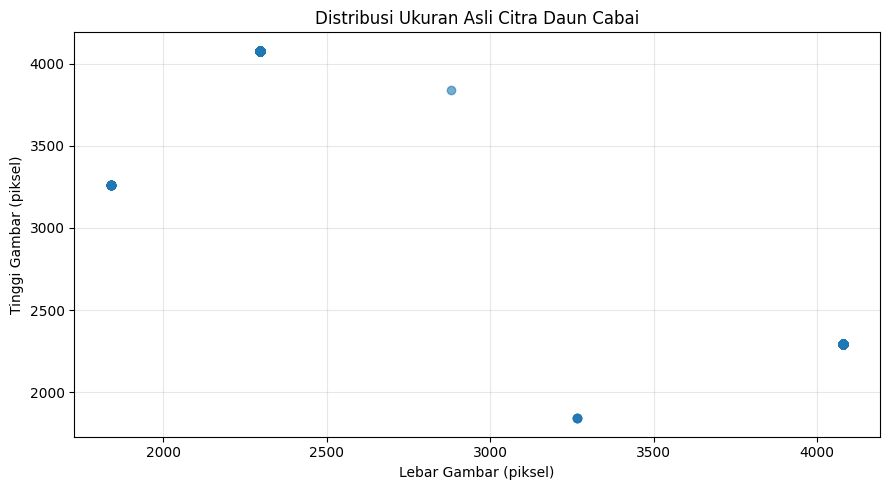

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df_sizes['width'],
    df_sizes['height'],
    alpha=0.6
)

plt.title('Distribusi Ukuran Asli Citra Daun Cabai')
plt.xlabel('Lebar Gambar (piksel)')
plt.ylabel('Tinggi Gambar (piksel)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Statistik rasio gambar:
count    738.000000
mean       0.799937
std        0.481408
min        0.562745
25%        0.562745
50%        0.562745
75%        0.562745
max        1.777003
Name: aspect_ratio, dtype: float64


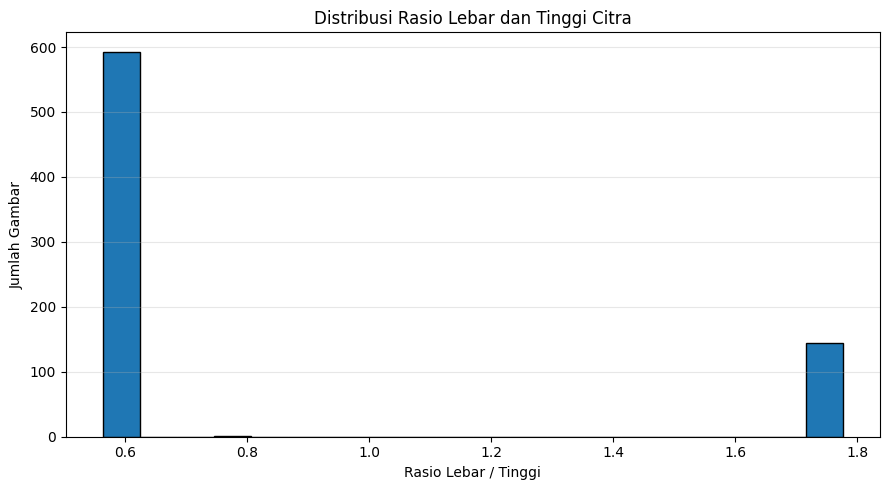

In [ ]:
df_sizes['aspect_ratio'] = (
    df_sizes['width'] / df_sizes['height']
)

print("Statistik rasio gambar:")
print(df_sizes['aspect_ratio'].describe())

plt.figure(figsize=(9, 5))

plt.hist(
    df_sizes['aspect_ratio'],
    bins=20,
    edgecolor='black'
)

plt.title('Distribusi Rasio Lebar dan Tinggi Citra')
plt.xlabel('Rasio Lebar / Tinggi')
plt.ylabel('Jumlah Gambar')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import os
import random

SEED = 42

IMG_SIZE = 224
BATCH_SIZE = 32

EPOCHS = 30
LEARNING_RATE = 0.0001

AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPU yang tersedia:", tf.config.list_physical_devices('GPU'))
print("Ukuran gambar:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow Version: 2.21.0
GPU yang tersedia: []
Ukuran gambar: 224
Batch size: 32


In [ ]:
label_encoder = LabelEncoder()

df['encoded_label'] = label_encoder.fit_transform(
    df['label']
)

class_names = list(label_encoder.classes_)

NUM_CLASSES = len(class_names)

print("Pemetaan label kelas:")

for index, class_name in enumerate(class_names):
    print(f"{class_name} = {index}")

print("\nJumlah kelas:", NUM_CLASSES)

display(df[['filepath', 'label', 'encoded_label']].head(10))

Pemetaan label kelas:
Daun karat = 0
Daun keriting = 1
Daun sehat = 2

Jumlah kelas: 3


,filepath,label,encoded_label
0,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
1,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
2,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
3,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
4,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
5,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
6,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
7,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
8,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0
9,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0


In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df['encoded_label']
)

print("Jumlah data training:", len(train_df))
print("Jumlah data sementara:", len(temp_df))

Jumlah data training: 516
Jumlah data sementara: 222


In [ ]:
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df['encoded_label']
)

print("================================")
print("HASIL PEMBAGIAN DATASET")
print("================================")

print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Testing    :", len(test_df))

print("Total      :", len(train_df) + len(val_df) + len(test_df))

HASIL PEMBAGIAN DATASET
Training   : 516
Validation : 111
Testing    : 111
Total      : 738


In [ ]:
distribution = pd.DataFrame({
    'Training': train_df['label'].value_counts(),
    'Validation': val_df['label'].value_counts(),
    'Testing': test_df['label'].value_counts()
}).fillna(0).astype(int)

print("Distribusi kelas setiap dataset:")
display(distribution)

Distribusi kelas setiap dataset:


,Training,Validation,Testing
label,,,
Daun karat,235,50,51
Daun keriting,181,39,39
Daun sehat,100,22,21


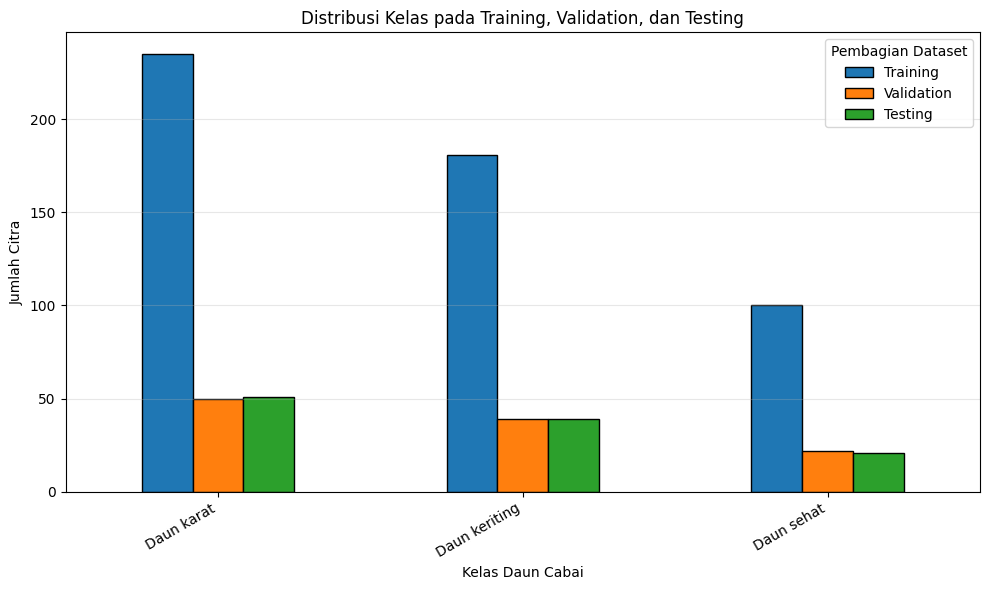

In [ ]:
distribution.plot(
    kind='bar',
    figsize=(10, 6),
    edgecolor='black'
)

plt.title('Distribusi Kelas pada Training, Validation, dan Testing')
plt.xlabel('Kelas Daun Cabai')
plt.ylabel('Jumlah Citra')

plt.xticks(rotation=30, ha='right')
plt.legend(title='Pembagian Dataset')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
train_df.to_csv(
    OUTPUT_DIR / 'train_dataset.csv',
    index=False
)

val_df.to_csv(
    OUTPUT_DIR / 'validation_dataset.csv',
    index=False
)

test_df.to_csv(
    OUTPUT_DIR / 'test_dataset.csv',
    index=False
)

print("Pembagian dataset berhasil disimpan.")

print("Lokasi:", OUTPUT_DIR)

Pembagian dataset berhasil disimpan.
Lokasi: /content/drive/MyDrive/Hasil_Penelitian_Cabai


In [ ]:
class_mapping = pd.DataFrame({
    'class_name': class_names,
    'class_index': range(len(class_names))
})

class_mapping.to_csv(
    OUTPUT_DIR / 'class_mapping.csv',
    index=False
)

display(class_mapping)

,class_name,class_index
0,Daun karat,0
1,Daun keriting,1
2,Daun sehat,2


In [ ]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.int32)

    return image, label

print("Fungsi preprocessing berhasil dibuat.")

Fungsi preprocessing berhasil dibuat.


In [ ]:
def create_dataset(dataframe, training=False):

    image_paths = dataframe['filepath'].values

    labels = dataframe['encoded_label'].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = create_dataset(
    train_df,
    training=True
)

val_dataset = create_dataset(
    val_df,
    training=False
)

test_dataset = create_dataset(
    test_df,
    training=False
)

print("Pipeline dataset berhasil dibuat.")

Pipeline dataset berhasil dibuat.


In [ ]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        mode='horizontal'
    ),

    tf.keras.layers.RandomRotation(
        factor=0.08
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10
    ),

    tf.keras.layers.RandomContrast(
        factor=0.10
    )

], name='data_augmentation')

print("Data augmentation berhasil dibuat.")

Data augmentation berhasil dibuat.


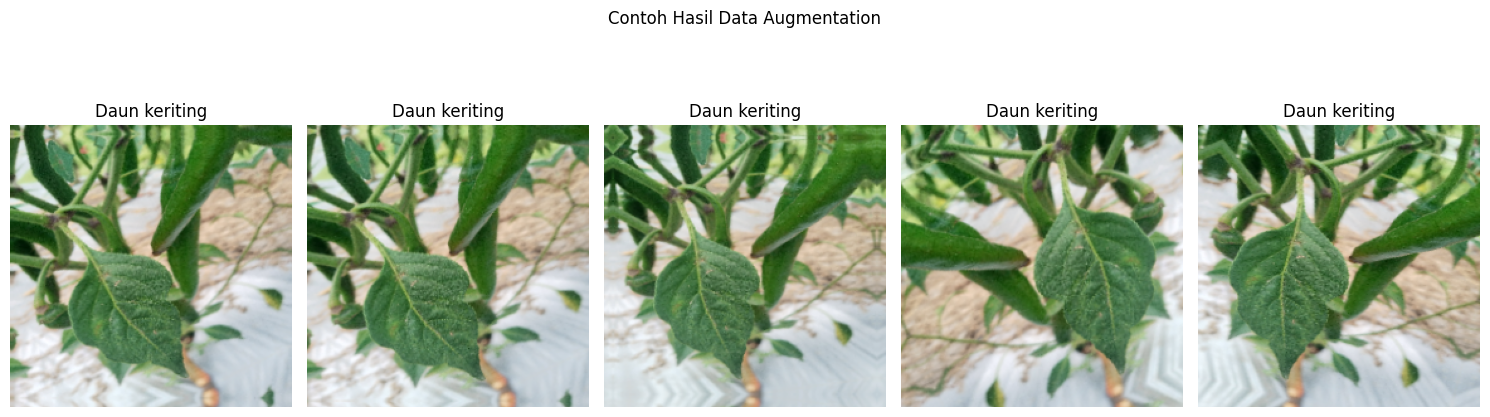

In [ ]:
sample_images, sample_labels = next(iter(train_dataset))

sample_image = sample_images[0]

sample_label = sample_labels[0].numpy()

plt.figure(figsize=(15, 5))

for i in range(5):

    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )

    augmented_image = tf.clip_by_value(
        augmented_image[0],
        0,
        255
    )

    plt.subplot(1, 5, i + 1)

    plt.imshow(
        augmented_image.numpy().astype('uint8')
    )

    plt.title(class_names[sample_label])

    plt.axis('off')

plt.suptitle('Contoh Hasil Data Augmentation')

plt.tight_layout()
plt.show()

In [ ]:
def augment_image(image, label):

    image = data_augmentation(
        image,
        training=True
    )

    image = tf.clip_by_value(
        image,
        0.0,
        255.0
    )

    return image, label


train_dataset_augmented = train_dataset.map(
    augment_image,
    num_parallel_calls=AUTOTUNE
)

train_dataset_augmented = train_dataset_augmented.prefetch(
    AUTOTUNE
)

print("Training dataset dengan augmentation berhasil dibuat.")

Training dataset dengan augmentation berhasil dibuat.


In [ ]:
for images, labels in train_dataset_augmented.take(1):

    print("Bentuk batch gambar:", images.shape)

    print("Bentuk batch label:", labels.shape)

    print("Tipe data gambar:", images.dtype)

    print("Tipe data label:", labels.dtype)

    print("Nilai minimum gambar:", tf.reduce_min(images).numpy())

    print("Nilai maksimum gambar:", tf.reduce_max(images).numpy())

Bentuk batch gambar: (32, 224, 224, 3)
Bentuk batch label: (32,)
Tipe data gambar: <dtype: 'float32'>
Tipe data label: <dtype: 'int32'>
Nilai minimum gambar: 0.0
Nilai maksimum gambar: 255.0


In [ ]:
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam

print("Library model berhasil diimpor.")

Library model berhasil diimpor.


In [ ]:
base_model = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

print("EfficientNetB0 berhasil dimuat.")
print("Jumlah layer:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 berhasil dimuat.
Jumlah layer: 238


In [ ]:
base_model.trainable = False

print("Status backbone:", base_model.trainable)

print(
    "Jumlah parameter yang dapat dilatih:",
    sum(
        tf.keras.backend.count_params(w)
        for w in base_model.trainable_weights
    )
)

print(
    "Jumlah parameter yang dibekukan:",
    sum(
        tf.keras.backend.count_params(w)
        for w in base_model.non_trainable_weights
    )
)

Status backbone: False
Jumlah parameter yang dapat dilatih: 0
Jumlah parameter yang dibekukan: 4049571.0


In [ ]:
inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name='input_image'
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name='global_average_pooling'
)(x)

x = layers.Dropout(
    0.30,
    name='dropout'
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax',
    name='classification_output'
)(x)

model_baseline = models.Model(
    inputs=inputs,
    outputs=outputs,
    name='EfficientNetB0_Baseline'
)

print("Model EfficientNetB0 Baseline berhasil dibuat.")

Model EfficientNetB0 Baseline berhasil dibuat.


In [ ]:
model_baseline.summary()

Model: "EfficientNetB0_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
total_params = model_baseline.count_params()

trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in model_baseline.trainable_weights
)

non_trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in model_baseline.non_trainable_weights
)

print("Total parameter       :", total_params)
print("Trainable parameter   :", trainable_params)
print("Non-trainable parameter:", non_trainable_params)

Total parameter       : 4053414
Trainable parameter   : 3843
Non-trainable parameter: 4049571.0


In [ ]:
model_baseline.compile(
    optimizer=Adam(
        learning_rate=LEARNING_RATE
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("Model berhasil di-compile.")

Model berhasil di-compile.


In [ ]:
checkpoint_path = str(
    BASELINE_DIR / 'best_efficientnetb0.keras'
)

callbacks_baseline = [

    EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )

]

print("Callback berhasil disiapkan.")
print("Model terbaik akan disimpan di:", checkpoint_path)

Callback berhasil disiapkan.
Model terbaik akan disimpan di: /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/best_efficientnetb0.keras


In [ ]:
history_baseline = model_baseline.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks_baseline,
    verbose=1
)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2739 - loss: 1.2656
Epoch 1: val_loss improved from None to 1.10742, saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/best_efficientnetb0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/best_efficientnetb0.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 58s 3s/step - accuracy: 0.3140 - loss: 1.2199 - val_accuracy: 0.3604 - val_loss: 1.1074 - learning_rate: 1.0000e-04
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4199 - loss: 1.1404
Epoch 2: val_loss improved from 1.10742 to 1.02772, saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/best_efficientnetb0.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/best_efficientnetb0.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 79s 3s/step - accuracy: 0.4205 - loss: 1.1203 - val_accuracy: 0.4324 - val_loss: 1.0277 - learning_rate: 1.0000e-

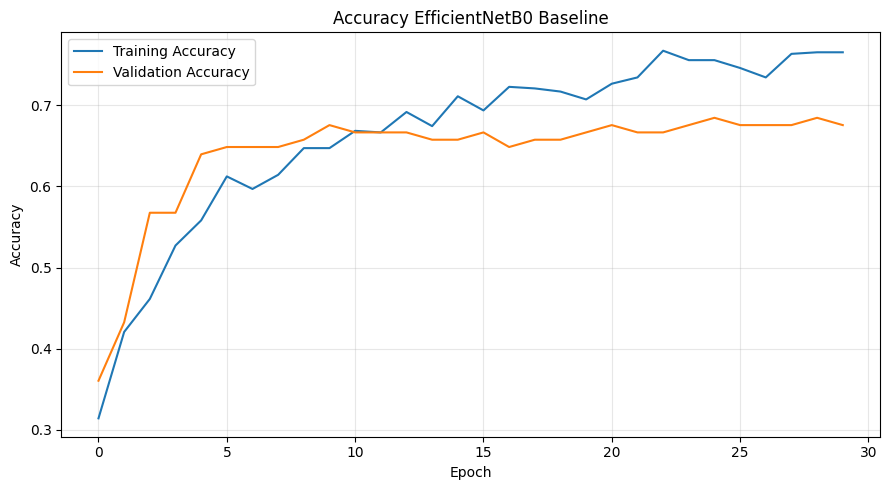

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_baseline.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_baseline.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Accuracy EfficientNetB0 Baseline')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

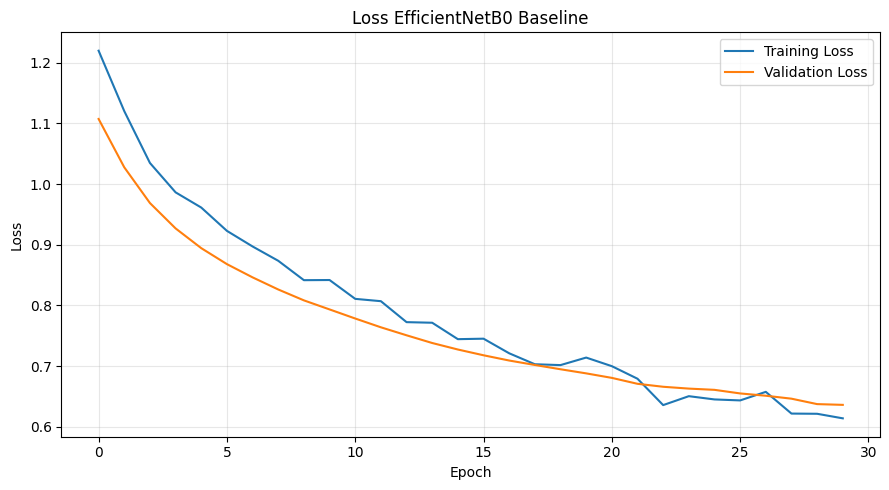

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_baseline.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_baseline.history['val_loss'],
    label='Validation Loss'
)

plt.title('Loss EfficientNetB0 Baseline')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
final_model_path = str(
    BASELINE_DIR / 'efficientnetb0_baseline_final.keras'
)

model_baseline.save(final_model_path)

print("Model berhasil disimpan.")
print("Lokasi:", final_model_path)

Model berhasil disimpan.
Lokasi: /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/efficientnetb0_baseline_final.keras


In [ ]:
history_df = pd.DataFrame(
    history_baseline.history
)

history_df.to_csv(
    BASELINE_DIR / 'training_history.csv',
    index=False
)

display(history_df.tail())

print("Riwayat training berhasil disimpan.")

,accuracy,loss,val_accuracy,val_loss,learning_rate
25,0.746124,0.643548,0.675676,0.655054,0.0001
26,0.734496,0.657664,0.675676,0.651261,0.0001
27,0.763566,0.621854,0.675676,0.646403,0.0001
28,0.765504,0.621517,0.684685,0.637460,0.0001
29,0.765504,0.614004,0.675676,0.636220,0.0001


Riwayat training berhasil disimpan.


In [ ]:
for index, layer in enumerate(base_model.layers):

    print(
        index,
        layer.name,
        layer.output.shape
    )

0 input_layer_1 (None, 224, 224, 3)
1 rescaling (None, 224, 224, 3)
2 normalization (None, 224, 224, 3)
3 rescaling_1 (None, 224, 224, 3)
4 stem_conv_pad (None, 225, 225, 3)
5 stem_conv (None, 112, 112, 32)
6 stem_bn (None, 112, 112, 32)
7 stem_activation (None, 112, 112, 32)
8 block1a_dwconv (None, 112, 112, 32)
9 block1a_bn (None, 112, 112, 32)
10 block1a_activation (None, 112, 112, 32)
11 block1a_se_squeeze (None, 32)
12 block1a_se_reshape (None, 1, 1, 32)
13 block1a_se_reduce (None, 1, 1, 8)
14 block1a_se_expand (None, 1, 1, 32)
15 block1a_se_excite (None, 112, 112, 32)
16 block1a_project_conv (None, 112, 112, 16)
17 block1a_project_bn (None, 112, 112, 16)
18 block2a_expand_conv (None, 112, 112, 96)
19 block2a_expand_bn (None, 112, 112, 96)
20 block2a_expand_activation (None, 112, 112, 96)
21 block2a_dwconv_pad (None, 113, 113, 96)
22 block2a_dwconv (None, 56, 56, 96)
23 block2a_bn (None, 56, 56, 96)
24 block2a_activation (None, 56, 56, 96)
25 block2a_se_squeeze (None, 96)
26 block

In [ ]:
available_layers = [
    layer.name for layer in base_model.layers
]

required_layers = [
    'block3a_expand_activation',
    'top_activation'
]

for layer_name in required_layers:

    if layer_name in available_layers:
        print(f"Layer ditemukan: {layer_name}")
    else:
        print(f"Layer tidak ditemukan: {layer_name}")

if not all(
    name in available_layers
    for name in required_layers
):
    raise ValueError(
        "Nama layer tidak sesuai. Periksa hasil Cell 39."
    )

Layer ditemukan: block3a_expand_activation
Layer ditemukan: top_activation


In [ ]:
cross_base = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

cross_base.trainable = False

print("Backbone Cross-Attention berhasil dimuat.")
print("Jumlah layer:", len(cross_base.layers))

Backbone Cross-Attention berhasil dimuat.
Jumlah layer: 238


In [ ]:
early_feature = cross_base.get_layer(
    'block3a_expand_activation'
).output

deep_feature = cross_base.get_layer(
    'top_activation'
).output

feature_extractor = tf.keras.Model(
    inputs=cross_base.input,
    outputs=[
        early_feature,
        deep_feature
    ],
    name='EfficientNetB0_Feature_Extractor'
)

print("Feature extractor berhasil dibuat.")

print(
    "Bentuk fitur awal:",
    feature_extractor.output[0].shape
)

print(
    "Bentuk fitur dalam:",
    feature_extractor.output[1].shape
)

Feature extractor berhasil dibuat.
Bentuk fitur awal: (None, 56, 56, 144)
Bentuk fitur dalam: (None, 7, 7, 1280)


In [ ]:
inputs_ca = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name='input_image'
)

augmented = data_augmentation(inputs_ca)

early_map, deep_map = feature_extractor(
    augmented,
    training=False
)

print("Input dan ekstraksi fitur berhasil dibuat.")

Input dan ekstraksi fitur berhasil dibuat.


In [ ]:
EMBEDDING_DIM = 128
NUM_HEADS = 4
KEY_DIM = 32

early_projected = layers.Conv2D(
    filters=EMBEDDING_DIM,
    kernel_size=1,
    padding='same',
    name='early_feature_projection'
)(early_map)

deep_projected = layers.Conv2D(
    filters=EMBEDDING_DIM,
    kernel_size=1,
    padding='same',
    name='deep_feature_projection'
)(deep_map)

print("Proyeksi fitur berhasil dibuat.")

Proyeksi fitur berhasil dibuat.


In [ ]:
early_tokens = layers.Reshape(
    (-1, EMBEDDING_DIM),
    name='early_feature_tokens'
)(early_projected)

deep_tokens = layers.Reshape(
    (-1, EMBEDDING_DIM),
    name='deep_feature_tokens'
)(deep_projected)

print("Token fitur berhasil dibuat.")

Token fitur berhasil dibuat.


In [ ]:
cross_attention = layers.MultiHeadAttention(
    num_heads=NUM_HEADS,
    key_dim=KEY_DIM,
    dropout=0.10,
    name='cross_attention'
)(
    query=deep_tokens,
    key=early_tokens,
    value=early_tokens
)

print("Cross-Attention berhasil dibuat.")

Cross-Attention berhasil dibuat.


In [ ]:
query=deep_tokens,
key=early_tokens,
value=early_tokens

In [ ]:
attention_output = layers.Add(
    name='attention_residual'
)(
    [deep_tokens, cross_attention]
)

attention_output = layers.LayerNormalization(
    epsilon=1e-6,
    name='attention_layer_normalization'
)(attention_output)

print("Residual connection dan normalisasi berhasil dibuat.")

Residual connection dan normalisasi berhasil dibuat.


In [ ]:
x_ca = layers.GlobalAveragePooling1D(
    name='cross_attention_global_pooling'
)(attention_output)

x_ca = layers.Dropout(
    0.30,
    name='cross_attention_dropout'
)(x_ca)

print("Pooling dan Dropout berhasil dibuat.")

Pooling dan Dropout berhasil dibuat.


In [ ]:
outputs_ca = layers.Dense(
    NUM_CLASSES,
    activation='softmax',
    name='cross_attention_classification_output'
)(x_ca)

print("Output klasifikasi berhasil dibuat.")

Output klasifikasi berhasil dibuat.


In [ ]:
model_cross_attention = tf.keras.Model(
    inputs=inputs_ca,
    outputs=outputs_ca,
    name='EfficientNetB0_CrossAttention'
)

print("Model EfficientNetB0 + Cross-Attention berhasil dibuat.")

Model EfficientNetB0 + Cross-Attention berhasil dibuat.


In [ ]:
model_cross_attention.summary()

Model: "EfficientNetB0_CrossAttention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_image[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EfficientNetB0_Fea… │ [(None, 56, 56,   │  4,049,571 │ data_augmentatio… │
│ (Functional)        │ 144), (None, 7,   │            │                   │
│                     │ 7, 1280)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_feature_proje… │ (None, 7, 7, 128) │    163,968 │ EfficientNetB0_F… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ early_feature_proj… │ (None, 56, 56,    │     18,560 │ EfficientNetB0_F… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ deep_feature_tokens │ (None, 49, 128)   │          0 │ deep_feature_pro… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ early_feature_toke… │ (None, 3136, 128) │          0 │ early_feature_pr… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_attention     │ (None, 49, 128)   │     66,048 │ early_feature_to… │
│ (MultiHeadAttentio… │                   │            │ deep_feature_tok… │
│                     │                   │            │ early_feature_to… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_residual  │ (None, 49, 128)   │          0 │ deep_feature_tok… │
│ (Add)               │                   │            │ cross_attention[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_layer_no… │ (None, 49, 128)   │        256 │ attention_residu… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_attention_gl… │ (None, 128)       │          0 │ attention_layer_… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_attention_dr… │ (None, 128)       │          0 │ cross_attention_… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_attention_cl… │ (None, 3)         │        387 │ cross_attention_… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,298,790 (16.40 MB)

 Trainable params: 249,219 (973.51 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
total_params_ca = model_cross_attention.count_params()

trainable_params_ca = sum(
    tf.keras.backend.count_params(w)
    for w in model_cross_attention.trainable_weights
)

non_trainable_params_ca = sum(
    tf.keras.backend.count_params(w)
    for w in model_cross_attention.non_trainable_weights
)

print("Total parameter        :", total_params_ca)
print("Trainable parameter    :", trainable_params_ca)
print("Non-trainable parameter:", non_trainable_params_ca)

Total parameter        : 4298790
Trainable parameter    : 249219
Non-trainable parameter: 4049571.0


In [ ]:
model_cross_attention.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("Model Cross-Attention berhasil di-compile.")

Model Cross-Attention berhasil di-compile.


In [ ]:
checkpoint_ca_path = str(
    ATTENTION_DIR / 'best_cross_attention.keras'
)

callbacks_cross_attention = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_ca_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )

]

print("Callback Cross-Attention berhasil disiapkan.")

Callback Cross-Attention berhasil disiapkan.


In [ ]:
history_cross_attention = model_cross_attention.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks_cross_attention,
    verbose=1
)

Epoch 1/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3973 - loss: 1.1658
Epoch 1: val_loss improved from None to 0.82313, saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0_CrossAttention/best_cross_attention.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0_CrossAttention/best_cross_attention.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 90s 5s/step - accuracy: 0.4477 - loss: 1.0762 - val_accuracy: 0.6396 - val_loss: 0.8231 - learning_rate: 1.0000e-04
Epoch 2/30
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6070 - loss: 0.8792
Epoch 2: val_loss improved from 0.82313 to 0.73271, saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0_CrossAttention/best_cross_attention.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0_CrossAttention/best_cross_attention.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 70s 4s/step - accuracy: 0.6318 - loss: 0.8337 - v

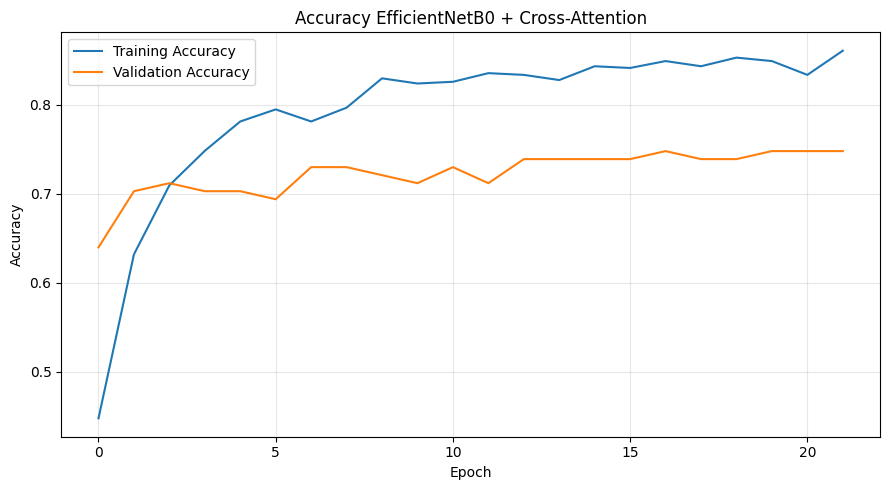

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_cross_attention.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_cross_attention.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Accuracy EfficientNetB0 + Cross-Attention')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

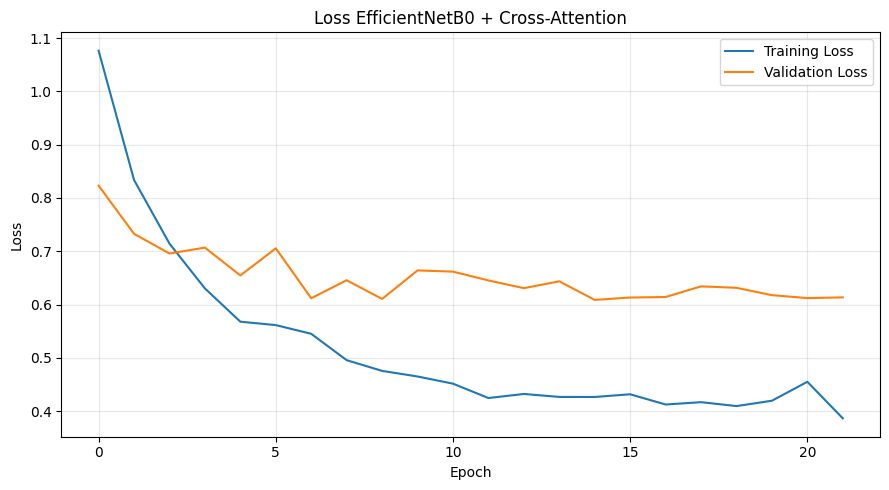

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_cross_attention.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_cross_attention.history['val_loss'],
    label='Validation Loss'
)

plt.title('Loss EfficientNetB0 + Cross-Attention')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
history_ca_df = pd.DataFrame(
    history_cross_attention.history
)

history_ca_df.to_csv(
    ATTENTION_DIR / 'training_history.csv',
    index=False
)

display(history_ca_df.tail())

print("Riwayat training Cross-Attention berhasil disimpan.")

,accuracy,loss,val_accuracy,val_loss,learning_rate
17,0.843023,0.416896,0.738739,0.634160,2.000000e-05
18,0.852713,0.409559,0.738739,0.631423,4.000000e-06
19,0.848837,0.419583,0.747748,0.617700,4.000000e-06
20,0.833333,0.455153,0.747748,0.612123,4.000000e-06
21,0.860465,0.386554,0.747748,0.613477,8.000000e-07


Riwayat training Cross-Attention berhasil disimpan.


In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Model baseline tersedia:",
      'model_baseline' in globals())

print("Model Cross-Attention tersedia:",
      'model_cross_attention' in globals())

print("Test dataset tersedia:",
      'test_dataset' in globals())

print("Jumlah data testing:", len(test_df))
print("Jumlah kelas:", NUM_CLASSES)
print("Nama kelas:", class_names)

Model baseline tersedia: True
Model Cross-Attention tersedia: True
Test dataset tersedia: True
Jumlah data testing: 111
Jumlah kelas: 3
Nama kelas: ['Daun karat', 'Daun keriting', 'Daun sehat']


In [ ]:
baseline_model_path = str(
    BASELINE_DIR / 'best_efficientnetb0.keras'
)

cross_attention_model_path = str(
    ATTENTION_DIR / 'best_cross_attention.keras'
)

if 'model_baseline' not in globals():

    model_baseline = tf.keras.models.load_model(
        baseline_model_path
    )

if 'model_cross_attention' not in globals():

    model_cross_attention = tf.keras.models.load_model(
        cross_attention_model_path
    )

print("Kedua model berhasil diperiksa atau dimuat.")

Kedua model berhasil diperiksa atau dimuat.


In [ ]:
y_true_list = []

for images, labels in test_dataset:

    y_true_list.extend(
        labels.numpy().tolist()
    )

y_true = np.array(y_true_list)

print("Jumlah label sebenarnya:", len(y_true))
print("Distribusi label sebenarnya:")
print(pd.Series(y_true).value_counts().sort_index())

Jumlah label sebenarnya: 111
Distribusi label sebenarnya:
0    51
1    39
2    21
Name: count, dtype: int64


In [ ]:
y_pred_probability_baseline = model_baseline.predict(
    test_dataset,
    verbose=1
)

y_pred_baseline = np.argmax(
    y_pred_probability_baseline,
    axis=1
)

print("Prediksi baseline selesai.")
print("Jumlah hasil prediksi:", len(y_pred_baseline))

4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step
Prediksi baseline selesai.
Jumlah hasil prediksi: 111


In [ ]:
y_pred_probability_ca = model_cross_attention.predict(
    test_dataset,
    verbose=1
)

y_pred_ca = np.argmax(
    y_pred_probability_ca,
    axis=1
)

print("Prediksi Cross-Attention selesai.")
print("Jumlah hasil prediksi:", len(y_pred_ca))

4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step
Prediksi Cross-Attention selesai.
Jumlah hasil prediksi: 111


In [ ]:
assert len(y_true) == len(y_pred_baseline)
assert len(y_true) == len(y_pred_ca)

print("Jumlah label sebenarnya:", len(y_true))
print("Jumlah prediksi baseline:", len(y_pred_baseline))
print("Jumlah prediksi Cross-Attention:", len(y_pred_ca))

print("\nSemua jumlah data sudah sesuai.")

Jumlah label sebenarnya: 111
Jumlah prediksi baseline: 111
Jumlah prediksi Cross-Attention: 111

Semua jumlah data sudah sesuai.


In [ ]:
def calculate_metrics(y_true, y_pred, model_name):

    return {
        'Model': model_name,

        'Accuracy': accuracy_score(
            y_true,
            y_pred
        ),

        'Precision Macro': precision_score(
            y_true,
            y_pred,
            average='macro',
            zero_division=0
        ),

        'Recall Macro': recall_score(
            y_true,
            y_pred,
            average='macro',
            zero_division=0
        ),

        'F1-Score Macro': f1_score(
            y_true,
            y_pred,
            average='macro',
            zero_division=0
        ),

        'Precision Weighted': precision_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        ),

        'Recall Weighted': recall_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        ),

        'F1-Score Weighted': f1_score(
            y_true,
            y_pred,
            average='weighted',
            zero_division=0
        )
    }


print("Fungsi perhitungan metrik berhasil dibuat.")

Fungsi perhitungan metrik berhasil dibuat.


In [ ]:
baseline_metrics = calculate_metrics(
    y_true,
    y_pred_baseline,
    'EfficientNetB0 Baseline'
)

ca_metrics = calculate_metrics(
    y_true,
    y_pred_ca,
    'EfficientNetB0 + Cross-Attention'
)

comparison_df = pd.DataFrame([
    baseline_metrics,
    ca_metrics
])

display(
    comparison_df.style.format({
        col: '{:.4f}'
        for col in comparison_df.columns
        if col != 'Model'
    })
)

,Model,Accuracy,Precision Macro,Recall Macro,F1-Score Macro,Precision Weighted,Recall Weighted,F1-Score Weighted
0,EfficientNetB0 Baseline,0.7477,0.7604,0.6828,0.7019,0.7564,0.7477,0.7371
1,EfficientNetB0 + Cross-Attention,0.7568,0.7654,0.7040,0.7209,0.7723,0.7568,0.7503


In [ ]:
print("CLASSIFICATION REPORT")
print("EFFICIENTNETB0 BASELINE")
print("=" * 55)

print(
    classification_report(
        y_true,
        y_pred_baseline,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

CLASSIFICATION REPORT
EFFICIENTNETB0 BASELINE
               precision    recall  f1-score   support

   Daun karat     0.7077    0.9020    0.7931        51
Daun keriting     0.8235    0.7179    0.7671        39
   Daun sehat     0.7500    0.4286    0.5455        21

     accuracy                         0.7477       111
    macro avg     0.7604    0.6828    0.7019       111
 weighted avg     0.7564    0.7477    0.7371       111



In [ ]:
print("CLASSIFICATION REPORT")
print("EFFICIENTNETB0 + CROSS-ATTENTION")
print("=" * 55)

print(
    classification_report(
        y_true,
        y_pred_ca,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

CLASSIFICATION REPORT
EFFICIENTNETB0 + CROSS-ATTENTION
               precision    recall  f1-score   support

   Daun karat     0.7121    0.9216    0.8034        51
Daun keriting     0.8966    0.6667    0.7647        39
   Daun sehat     0.6875    0.5238    0.5946        21

     accuracy                         0.7568       111
    macro avg     0.7654    0.7040    0.7209       111
 weighted avg     0.7723    0.7568    0.7503       111



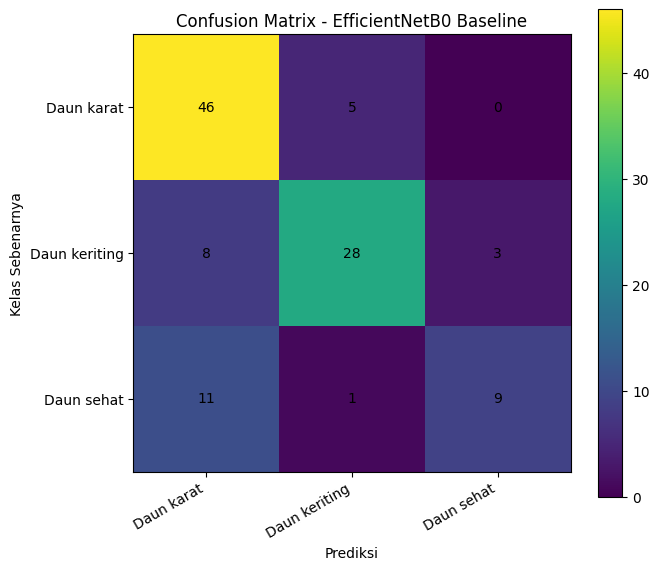

In [ ]:
cm_baseline = confusion_matrix(
    y_true,
    y_pred_baseline,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(7, 6))

plt.imshow(cm_baseline)

plt.title('Confusion Matrix - EfficientNetB0 Baseline')
plt.xlabel('Prediksi')
plt.ylabel('Kelas Sebenarnya')

plt.xticks(
    ticks=np.arange(NUM_CLASSES),
    labels=class_names,
    rotation=30,
    ha='right'
)

plt.yticks(
    ticks=np.arange(NUM_CLASSES),
    labels=class_names
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_baseline[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

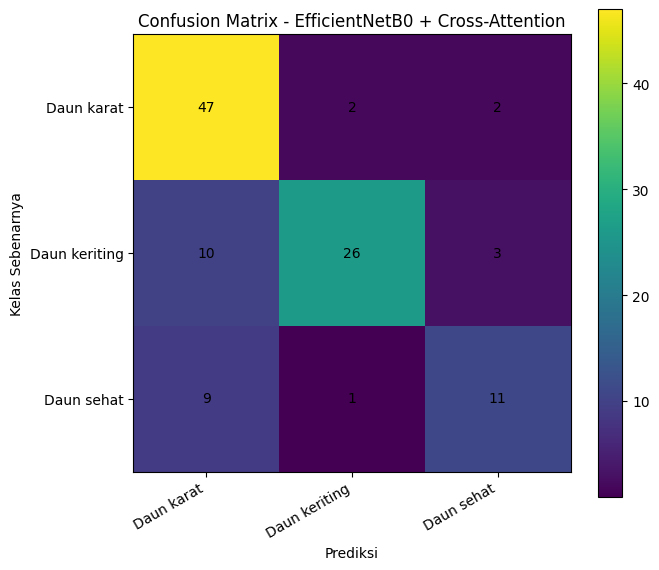

In [ ]:
cm_ca = confusion_matrix(
    y_true,
    y_pred_ca,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(7, 6))

plt.imshow(cm_ca)

plt.title('Confusion Matrix - EfficientNetB0 + Cross-Attention')
plt.xlabel('Prediksi')
plt.ylabel('Kelas Sebenarnya')

plt.xticks(
    ticks=np.arange(NUM_CLASSES),
    labels=class_names,
    rotation=30,
    ha='right'
)

plt.yticks(
    ticks=np.arange(NUM_CLASSES),
    labels=class_names
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_ca[i, j],
            ha='center',
            va='center'
        )

plt.colorbar()
plt.tight_layout()
plt.show()

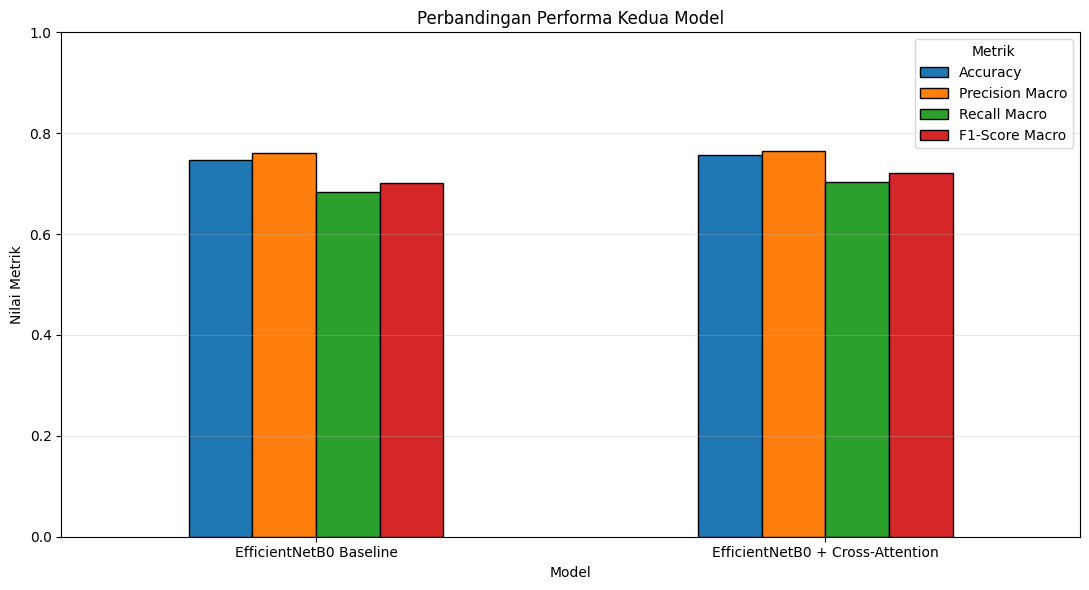

In [ ]:
metrics_to_plot = [
    'Accuracy',
    'Precision Macro',
    'Recall Macro',
    'F1-Score Macro'
]

comparison_plot = comparison_df.set_index('Model')[
    metrics_to_plot
]

comparison_plot.plot(
    kind='bar',
    figsize=(11, 6),
    edgecolor='black'
)

plt.title('Perbandingan Performa Kedua Model')
plt.xlabel('Model')
plt.ylabel('Nilai Metrik')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title='Metrik')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
baseline_row = comparison_df.iloc[0]
ca_row = comparison_df.iloc[1]

metric_names = [
    'Accuracy',
    'Precision Macro',
    'Recall Macro',
    'F1-Score Macro'
]

difference_data = []

for metric in metric_names:

    baseline_value = baseline_row[metric]
    ca_value = ca_row[metric]

    difference = ca_value - baseline_value

    difference_data.append({
        'Metrik': metric,
        'Baseline': baseline_value,
        'Cross-Attention': ca_value,
        'Selisih': difference,
        'Perubahan (poin persentase)': difference * 100
    })

difference_df = pd.DataFrame(difference_data)

display(
    difference_df.style.format({
        'Baseline': '{:.4f}',
        'Cross-Attention': '{:.4f}',
        'Selisih': '{:+.4f}',
        'Perubahan (poin persentase)': '{:+.2f}'
    })
)

,Metrik,Baseline,Cross-Attention,Selisih,Perubahan (poin persentase)
0,Accuracy,0.7477,0.7568,+0.0090,+0.90
1,Precision Macro,0.7604,0.7654,+0.0050,+0.50
2,Recall Macro,0.6828,0.7040,+0.0212,+2.12
3,F1-Score Macro,0.7019,0.7209,+0.0190,+1.90


In [ ]:
comparison_df.to_csv(
    OUTPUT_DIR / 'perbandingan_performa_model.csv',
    index=False
)

difference_df.to_csv(
    OUTPUT_DIR / 'selisih_performa_model.csv',
    index=False
)

print("Tabel perbandingan berhasil disimpan.")

Tabel perbandingan berhasil disimpan.


In [ ]:
pd.DataFrame(
    cm_baseline,
    index=class_names,
    columns=class_names
).to_csv(
    OUTPUT_DIR / 'confusion_matrix_baseline.csv'
)

pd.DataFrame(
    cm_ca,
    index=class_names,
    columns=class_names
).to_csv(
    OUTPUT_DIR / 'confusion_matrix_cross_attention.csv'
)

print("Confusion Matrix berhasil disimpan.")

Confusion Matrix berhasil disimpan.


In [ ]:
prediction_results = test_df[
    ['filepath', 'label', 'encoded_label']
].copy()

prediction_results['prediksi_baseline'] = [
    class_names[index]
    for index in y_pred_baseline
]

prediction_results['prediksi_cross_attention'] = [
    class_names[index]
    for index in y_pred_ca
]

prediction_results['baseline_benar'] = (
    prediction_results['encoded_label']
    == y_pred_baseline
)

prediction_results['cross_attention_benar'] = (
    prediction_results['encoded_label']
    == y_pred_ca
)

prediction_results.to_csv(
    OUTPUT_DIR / 'hasil_prediksi_testing.csv',
    index=False
)

display(prediction_results.head(10))

print("Hasil prediksi berhasil disimpan.")

,filepath,label,encoded_label,prediksi_baseline,prediksi_cross_attention,baseline_benar,cross_attention_benar
334,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun karat,Daun karat,True,True
552,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun karat,Daun karat,False,False
138,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun karat,Daun karat,True,True
386,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun keriting,Daun keriting,True,True
332,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun karat,Daun karat,True,True
276,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun karat,Daun karat,True,True
340,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun keriting,Daun keriting,True,True
121,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun karat,Daun karat,True,True
421,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun keriting,Daun keriting,True,True
652,/content/drive/MyDrive/Daun Cabai/Daun sehat/I...,Daun sehat,2,Daun sehat,Daun sehat,True,True


Hasil prediksi berhasil disimpan.


In [ ]:
wrong_predictions = prediction_results[
    (~prediction_results['baseline_benar'])
    |
    (~prediction_results['cross_attention_benar'])
].copy()

print(
    "Jumlah gambar yang salah diprediksi oleh minimal satu model:",
    len(wrong_predictions)
)

display(wrong_predictions.head(20))

Jumlah gambar yang salah diprediksi oleh minimal satu model: 36


,filepath,label,encoded_label,prediksi_baseline,prediksi_cross_attention,baseline_benar,cross_attention_benar
552,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun karat,Daun karat,False,False
460,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun keriting,Daun karat,True,False
13,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun keriting,Daun karat,False,True
371,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun sehat,Daun sehat,False,False
695,/content/drive/MyDrive/Daun Cabai/Daun sehat/I...,Daun sehat,2,Daun sehat,Daun karat,True,False
443,/content/drive/MyDrive/Daun Cabai/Daun keritin...,Daun keriting,1,Daun keriting,Daun sehat,True,False
174,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun keriting,Daun karat,False,True
721,/content/drive/MyDrive/Daun Cabai/Daun sehat/I...,Daun sehat,2,Daun karat,Daun sehat,False,True
613,/content/drive/MyDrive/Daun Cabai/Daun sehat/I...,Daun sehat,2,Daun karat,Daun sehat,False,True
1,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat,0,Daun keriting,Daun karat,False,True


In [ ]:
baseline_errors = (
    ~prediction_results['baseline_benar']
).sum()

ca_errors = (
    ~prediction_results['cross_attention_benar']
).sum()

print("Kesalahan Baseline:", baseline_errors)
print("Kesalahan Cross-Attention:", ca_errors)

if ca_errors < baseline_errors:
    print("Cross-Attention menghasilkan lebih sedikit kesalahan.")
elif ca_errors > baseline_errors:
    print("Baseline menghasilkan lebih sedikit kesalahan.")
else:
    print("Jumlah kesalahan kedua model sama.")

Kesalahan Baseline: 28
Kesalahan Cross-Attention: 27
Cross-Attention menghasilkan lebih sedikit kesalahan.
